# LeetCode #173: Binary Search Tree Iterator

https://leetcode.com/problems/binary-search-tree-iterator/

## Comparison of Approaches
| Approach | Time (next/hasNext) | Space |
|---|---|---|
| Precompute inorder list | O(1) amortized | O(n) |
| Controlled inorder traversal ★ | O(1) amortized / O(1) | O(h) |

## Understanding the Methods
### Precompute inorder list
Do a full inorder traversal at construction, store results in a list, use an index pointer. O(n) space.

### Optimal: Controlled inorder traversal ★
Use an explicit stack. Initialize by pushing all left-spine nodes. next() pops the top, processes it, then pushes the left-spine of its right child. This uses O(h) space where h is tree height, and each node is pushed/popped exactly once so amortized O(1) per call.

## Solutions
### C#

In [ ]:
public class TreeNode { public int val; public TreeNode left, right; public TreeNode(int v) { val = v; } }

public class BSTIterator {
    private Stack<TreeNode> stack = new();

    public BSTIterator(TreeNode root) => PushLeft(root);

    private void PushLeft(TreeNode node) {
        while (node != null) { stack.Push(node); node = node.left; }
    }

    public int Next() {
        var node = stack.Pop();
        PushLeft(node.right);
        return node.val;
    }

    public bool HasNext() => stack.Count > 0;
}

### Python

In [ ]:
class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val = val
        self.left = left
        self.right = right

class BSTIterator:
    def __init__(self, root: TreeNode):
        self.stack = []
        self._push_left(root)

    def _push_left(self, node):
        while node:
            self.stack.append(node)
            node = node.left

    def next(self) -> int:
        node = self.stack.pop()
        self._push_left(node.right)
        return node.val

    def hasNext(self) -> bool:
        return bool(self.stack)

### Go

In [ ]:
package main

import "fmt"

type TreeNode struct {
    Val   int
    Left  *TreeNode
    Right *TreeNode
}

type BSTIterator struct {
    stack []*TreeNode
}

func Constructor(root *TreeNode) BSTIterator {
    it := BSTIterator{}
    it.pushLeft(root)
    return it
}

func (it *BSTIterator) pushLeft(node *TreeNode) {
    for node != nil {
        it.stack = append(it.stack, node)
        node = node.Left
    }
}

func (it *BSTIterator) Next() int {
    n := len(it.stack)
    node := it.stack[n-1]
    it.stack = it.stack[:n-1]
    it.pushLeft(node.Right)
    return node.Val
}

func (it *BSTIterator) HasNext() bool { return len(it.stack) > 0 }

func main() {
    root := &TreeNode{7, &TreeNode{3, nil, nil}, &TreeNode{15, &TreeNode{9, nil, nil}, &TreeNode{20, nil, nil}}}
    it := Constructor(root)
    fmt.Println(it.Next())    // 3
    fmt.Println(it.Next())    // 7
    fmt.Println(it.HasNext()) // true
}

### Rust

In [ ]:
use std::collections::VecDeque;

#[derive(Debug)]
pub struct TreeNode {
    pub val: i32,
    pub left: Option<Box<TreeNode>>,
    pub right: Option<Box<TreeNode>>,
}

// Using precomputed inorder for Rust due to ownership complexity
pub struct BSTIterator {
    queue: VecDeque<i32>,
}

impl BSTIterator {
    pub fn new(root: Option<Box<TreeNode>>) -> Self {
        let mut queue = VecDeque::new();
        Self::inorder(&root, &mut queue);
        BSTIterator { queue }
    }

    fn inorder(node: &Option<Box<TreeNode>>, q: &mut VecDeque<i32>) {
        if let Some(n) = node {
            Self::inorder(&n.left, q);
            q.push_back(n.val);
            Self::inorder(&n.right, q);
        }
    }

    pub fn next(&mut self) -> i32 { self.queue.pop_front().unwrap() }
    pub fn has_next(&self) -> bool { !self.queue.is_empty() }
}

## Example Scenarios

### 1. Common Case — Controlled Inorder
**Input:** `BSTIterator([7,3,15,null,null,9,20]); next(); next(); ...`
Construction pushes the left spine $[7,3]$. Each $next()$ pops the top, then pushes the left spine of its right child, yielding sorted order $3,7,9,15,20$.

### 2. Slightly Complex — next() Pushes a Whole Left Spine
**Input:** `BSTIterator([2,1,12,null,null,7,null,4,9]); next(); next()`
After popping root $2$, its right child $12$ has a deep left spine, so $7$ and $4$ are pushed at once — the stack jumps to $[12,7,4]$ before returning $4$ next.

### 3. Edge Case: Time Factor — Amortized O(1)
**Input:** drain all $n$ nodes with repeated `next()`
Any single $next()$ may push several nodes, but across the whole traversal each node is pushed once and popped once — $2n$ stack ops over $n$ calls, so $O(1)$ amortized.

### 4. Edge Case: Space Factor — Left-Skewed Tree, O(h) Stack
**Input:** `BSTIterator([5,4,null,3,null,2])`
A fully left-leaning tree makes construction push the entire spine $[5,4,3,2]$, so the stack height equals the tree height $h$ — the worst-case $O(h)=O(n)$ space.

### 5. Almost-Impossible but Plausible — Right-Skewed Tree, O(1) Stack
**Input:** `BSTIterator([1,null,2,null,3,null,4])`
A right-leaning chain has no left spine, so the stack never holds more than one node — $O(1)$ space in this shape, each $next()$ pushing exactly one successor.


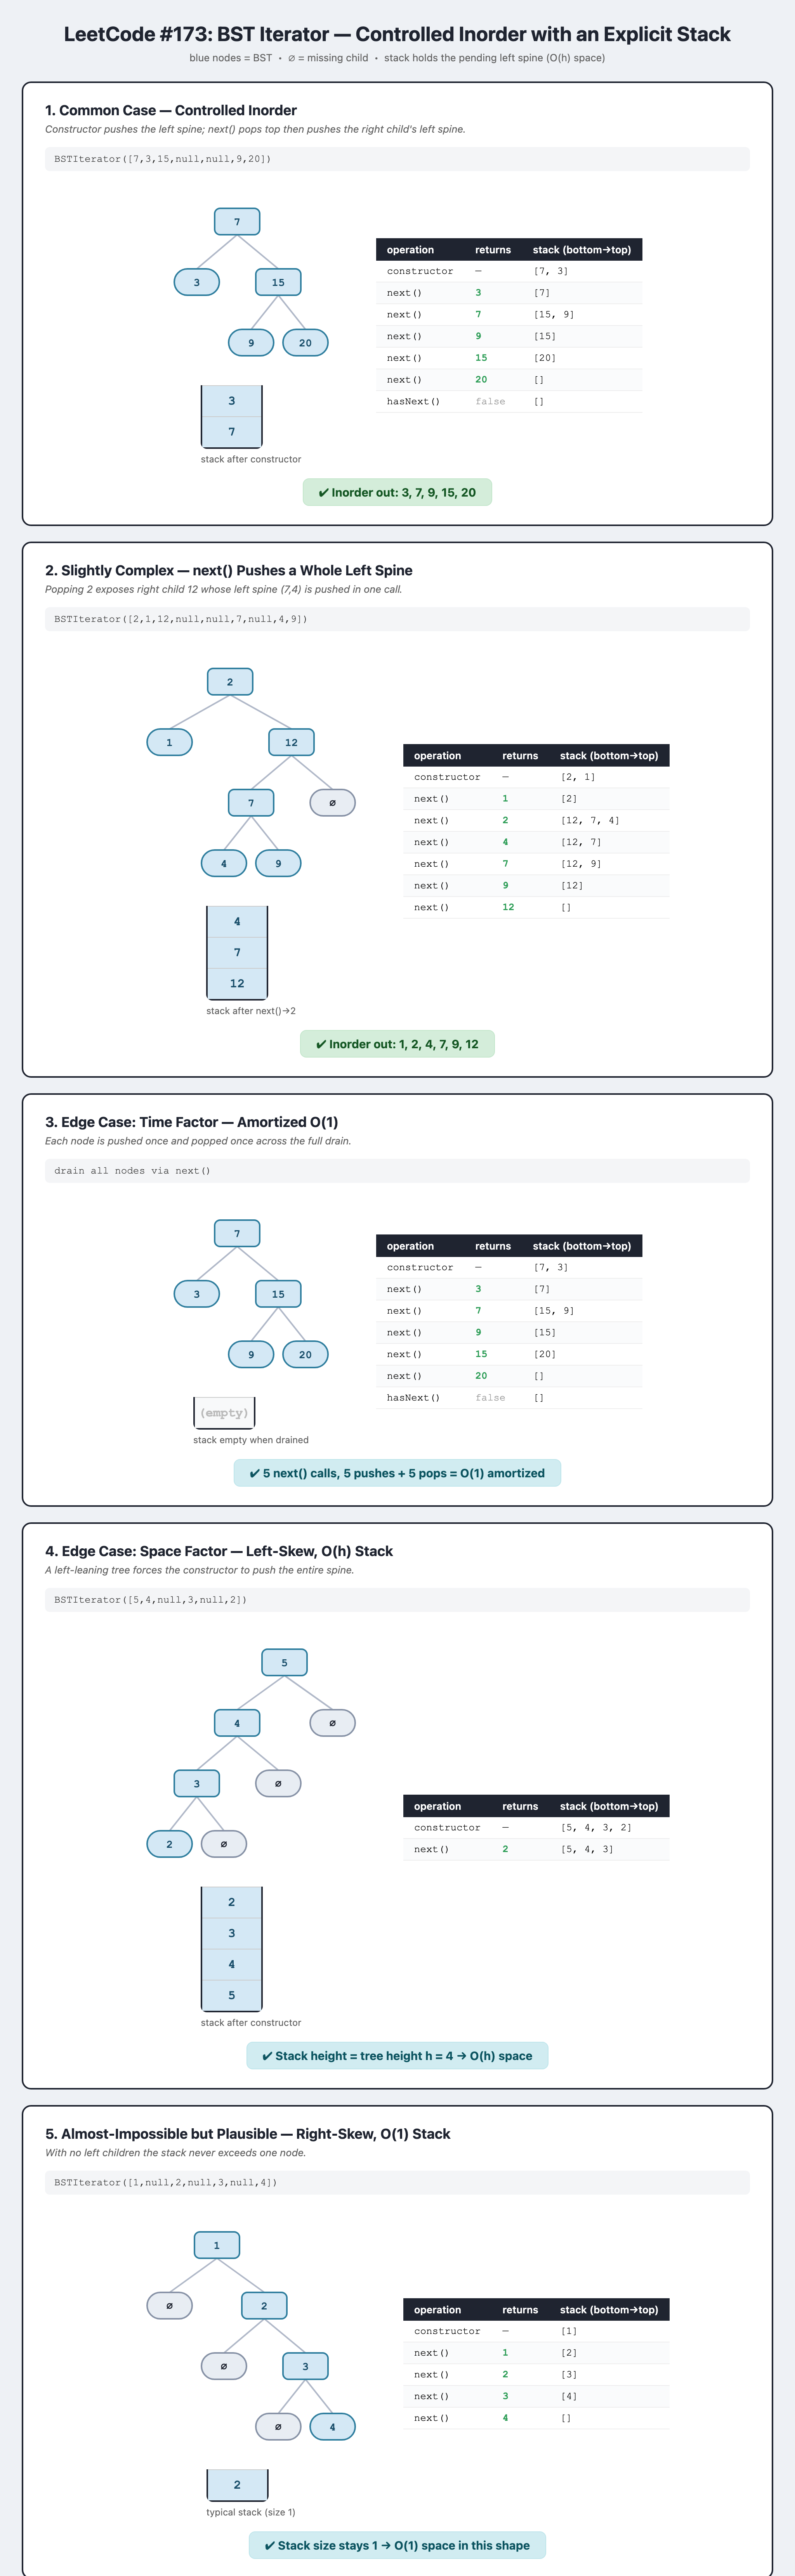